# 02b — CNN From Scratch: FINAL TRAINING (local GPU)

## Waste Classification AI — Phase 3

> **Run this notebook locally with a CUDA GPU** (developed/tested on an NVIDIA RTX 4050,
> CUDA 12.6, driver 610.88, via a dedicated project `.venv`). Device selection is automatic
> (`torch.device("cuda" if torch.cuda.is_available() else "cpu")`) — it also runs on CPU or
> on Colab if needed, just much slower. It trains the **from-scratch CNN**
> (`src/models/cnn.py`, identical architecture to the local smoke test) for a full epoch
> budget with early stopping, and produces the official Phase 3 result used in the Phase 6
> model comparison table.
>
> This is **not** the same thing as
> [`02a_cnn_from_scratch_smoke_test.ipynb`](02a_cnn_from_scratch_smoke_test.ipynb), which
> only ran 5 epochs on a CPU-only environment to verify the pipeline runs correctly — that
> notebook's ~47.6% test accuracy is a smoke-test result, not a final one, and is saved
> under clearly-labeled `*_smoke_test*` filenames so it can never be confused with the
> results this notebook produces. This notebook saves its results under the canonical
> filenames (`models/cnn_from_scratch_best.pt`, `reports/results/cnn_test_metrics.json`,
> etc.) — those are the ones that belong in the final report.
>
> Everything below — dataset, split, preprocessing, model architecture, and random seed —
> is identical to the smoke test. **The only difference is the epoch budget and the
> hardware it runs on.**


## 0. Environment Setup

Runs locally by default (adds the project root to `sys.path`); falls back to Colab's Drive
mount only if `google.colab` is detected. Device (CUDA vs. CPU) is selected automatically
in the next cell — no manual configuration needed either way.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Optional Colab fallback (not required -- this project runs locally on a CUDA GPU by default).
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/waste-classification-ai")  # <-- adjust if needed
    get_ipython().system(f"pip install -q -r {PROJECT_ROOT}/requirements.txt")

sys.path.insert(0, str(PROJECT_ROOT))
print(f"IN_COLAB = {IN_COLAB}")
print(f"PROJECT_ROOT = {PROJECT_ROOT}")


IN_COLAB = False
PROJECT_ROOT = C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project


In [2]:
import json

import torch
import torch.nn as nn

from src.data.dataset import WasteDataset
from src.data.download import download_trashnet
from src.data.splitter import create_stratified_split, load_split_manifest, save_split_manifest
from src.data.transforms import get_eval_transforms, get_train_transforms
from src.evaluation.metrics import (
    get_classification_report,
    get_classification_report_dict,
    get_predictions,
    plot_confusion_matrix,
    plot_training_curves,
)
from src.models.cnn import WasteCNN, count_parameters
from src.training.class_weights import compute_class_weights
from src.training.trainer import fit, save_history
from src.utils.config import (
    BATCH_SIZE,
    CLASS_NAMES,
    CNN_CHECKPOINT_PATH,
    FIGURES_DIR,
    RANDOM_SEED,
    RESULTS_DIR,
    SPLITS_MANIFEST_PATH,
)
from src.utils.device import get_device
from src.utils.seed import set_seed

set_seed(RANDOM_SEED)
device = get_device()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {device}")
print(f"CUDA available: {torch.cuda.is_available()}")
if not torch.cuda.is_available():
    print("WARNING: no GPU detected. In Colab: Runtime -> Change runtime type -> GPU.")

# Reproduces Phase 1/2 outputs if running fresh on a new Colab instance
download_trashnet()
if not SPLITS_MANIFEST_PATH.exists():
    manifest = create_stratified_split()
    save_split_manifest(manifest)
manifest = load_split_manifest()
print(f"Split manifest: {len(manifest)} images")


Device: cuda
CUDA available: True
Dataset already present at C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project\data\raw\dataset-resized, skipping download.
Split manifest: 2527 images


## 1. Data, Model, and Training Setup

Same `WasteDataset` + transforms as Phase 2, same `WasteCNN` architecture and
class-weighted loss as the smoke test — see
[`02a_cnn_from_scratch_smoke_test.ipynb`](02a_cnn_from_scratch_smoke_test.ipynb) or
[`src/models/cnn.py`](../src/models/cnn.py) for the full architecture rationale.


In [3]:
train_ds = WasteDataset(split="train", transform=get_train_transforms(), manifest=manifest)
val_ds = WasteDataset(split="val", transform=get_eval_transforms(), manifest=manifest)
test_ds = WasteDataset(split="test", transform=get_eval_transforms(), manifest=manifest)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

model = WasteCNN(num_classes=len(CLASS_NAMES), dropout=0.5)
print(model)
print(count_parameters(model))


Train: 1768 | Val: 379 | Test: 380
WasteCNN(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dil

In [4]:
# Full training budget (vs. 5 epochs in the local smoke test)
EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 1e-3

class_weights = compute_class_weights(manifest, split="train").to(device)
print("Class weights (order = CLASS_NAMES):")
for name, w in zip(CLASS_NAMES, class_weights.tolist()):
    print(f"  {name:<10s} {w:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(f"\nEPOCHS={EPOCHS}  PATIENCE={PATIENCE}  LEARNING_RATE={LEARNING_RATE}  BATCH_SIZE={BATCH_SIZE}")


Class weights (order = CLASS_NAMES):
  cardboard  1.045
  glass      0.842
  metal      1.027
  paper      0.708
  plastic    0.874
  trash      3.069

EPOCHS=30  PATIENCE=5  LEARNING_RATE=0.001  BATCH_SIZE=32


## 2. Training

In [5]:
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=EPOCHS,
    checkpoint_path=CNN_CHECKPOINT_PATH,
    patience=PATIENCE,
)

save_history(history, RESULTS_DIR / "cnn_training_history.json")
print(f"\nBest model checkpoint saved to {CNN_CHECKPOINT_PATH}")


Epoch   1/30 | train_loss=1.4917 train_acc=0.4027 | val_loss=1.3445 val_acc=0.3931 | 30.5s  [best, checkpoint saved]


Epoch   2/30 | train_loss=1.3878 train_acc=0.4451 | val_loss=1.3448 val_acc=0.3641 | 27.4s


Epoch   3/30 | train_loss=1.3298 train_acc=0.4570 | val_loss=1.2266 val_acc=0.5092 | 28.2s  [best, checkpoint saved]


Epoch   4/30 | train_loss=1.2903 train_acc=0.4802 | val_loss=1.1103 val_acc=0.5805 | 27.6s  [best, checkpoint saved]


Epoch   5/30 | train_loss=1.2342 train_acc=0.5164 | val_loss=1.1311 val_acc=0.5963 | 27.7s


...

Epoch  26/30 | train_loss=0.9509 train_acc=0.6414 | val_loss=0.9496 val_acc=0.6596 | 25.5s


Epoch  27/30 | train_loss=0.9415 train_acc=0.6442 | val_loss=0.8812 val_acc=0.7150 | 24.6s


Epoch  28/30 | train_loss=0.8992 train_acc=0.6669 | val_loss=0.9977 val_acc=0.6201 | 24.7s


Epoch  29/30 | train_loss=0.9104 train_acc=0.6646 | val_loss=0.9012 val_acc=0.6807 | 25.0s


Epoch  30/30 | train_loss=0.8800 train_acc=0.6827 | val_loss=0.8354 val_acc=0.6834 | 24.2s  [best, checkpoint saved]

Best model checkpoint saved to C:\Users\Martin\Downloads\Amit Data Science\projects\Deep Learning Project\models\cnn_from_scratch_best.pt


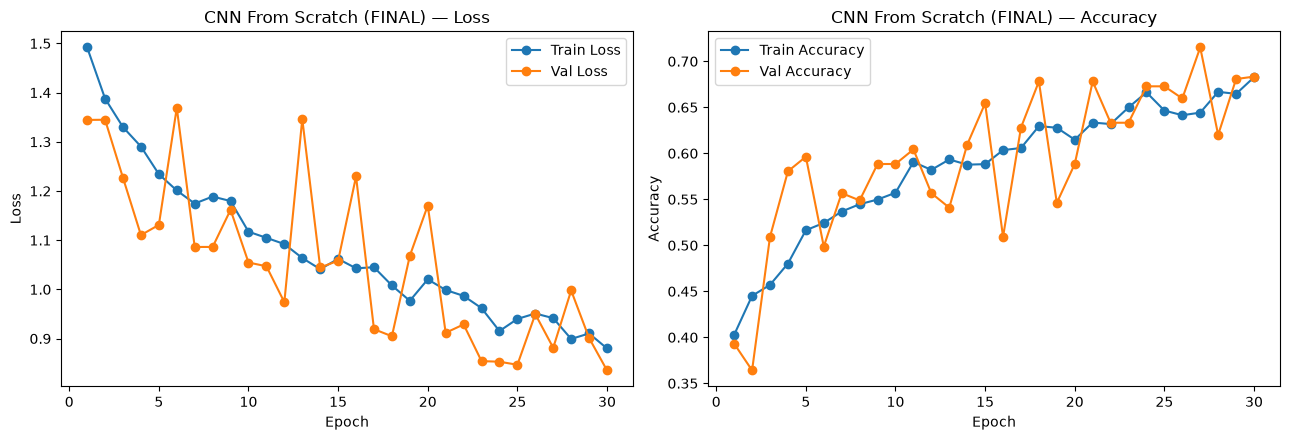

In [6]:
fig = plot_training_curves(history, title_prefix="CNN From Scratch (FINAL) — ",
                            save_path=FIGURES_DIR / "cnn_training_curves.png")


**Reading the curves (Final Local GPU Training, 30/30 epochs, RTX 4050):** Train loss
falls smoothly and consistently across all 30 epochs (1.49 -> 0.88) with train accuracy
rising from 40% to 68%. Validation loss is noisier (expected — the validation set is only
379 images) but the noise sits *around* a clear downward trend, ending at its lowest point
of the entire run (0.835) exactly at epoch 30 — **early stopping never triggered** because
validation loss kept setting new lows within every 5-epoch window. Train and validation
curves stay close together throughout, and validation loss is occasionally *below* train
loss late in training (e.g. epochs 23-25) — the signature of a **good, not-yet-overfit
fit**, not underfitting or overfitting. The clearest takeaway: **the model was still
improving when training stopped at the epoch budget, not because it plateaued.** A longer
budget (e.g. 50-60 epochs) would likely improve results further — a natural first line
item for Future Improvements.


## 3. Test Set Evaluation

Loads the **best checkpoint** (lowest validation loss, not necessarily the last epoch) and
evaluates once on the held-out test set.


In [7]:
model.load_state_dict(torch.load(CNN_CHECKPOINT_PATH, map_location=device))
model.to(device)

y_true, y_pred, y_probs = get_predictions(model, test_loader, device)
test_accuracy = (y_true == y_pred).mean()

print(f"Test accuracy: {test_accuracy:.4f}\n")
print(get_classification_report(y_true, y_pred, CLASS_NAMES))


Test accuracy: 0.6368

              precision    recall  f1-score   support

   cardboard      0.887     0.783     0.832        60
       glass      0.544     0.737     0.626        76
       metal      0.722     0.419     0.531        62
       paper      0.942     0.551     0.695        89
     plastic      0.623     0.658     0.640        73
       trash      0.271     0.800     0.405        20

    accuracy                          0.637       380
   macro avg      0.665     0.658     0.621       380
weighted avg      0.721     0.637     0.650       380



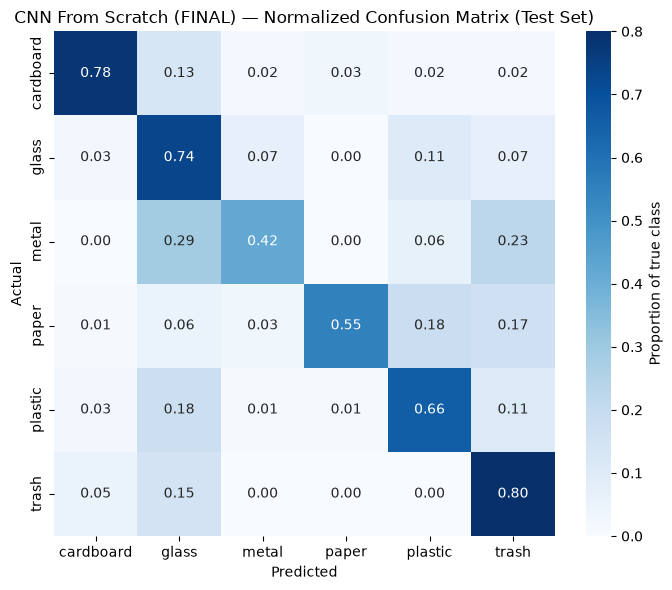

In [8]:
fig = plot_confusion_matrix(
    y_true, y_pred, CLASS_NAMES, normalize=True,
    title="CNN From Scratch (FINAL) — Normalized Confusion Matrix (Test Set)",
    save_path=FIGURES_DIR / "cnn_confusion_matrix.png",
)


**Which classes are hardest, and why (Final Local GPU Training):** Looking at the
confusion matrix above:
- **`cardboard` (78%) and `trash` (80%) have the highest recall**, `glass` close behind
  (74%). Cardboard's distinctive texture/color remains the easiest signal to learn, as
  predicted from the Phase 1 EDA.
- **`metal` is the weakest class (42% recall)** — confused mainly with `glass` (29%) and
  `trash` (23%). This actually sharpens the Phase 1 EDA hypothesis: it wasn't
  `glass`/`plastic` confusion that turned out to dominate, it was **metal being mistaken
  for glass** — plausible given both classes include shiny, reflective, cylindrical
  containers (cans vs. bottles) under the same studio lighting.
- **`paper` has very high precision (94%) but moderate recall (55%)** — when the model
  predicts paper, it's almost always right, but it misses nearly half of actual paper
  images, most often confusing them with `plastic` (18%) and `trash` (17%). This precision/
  recall gap suggests paper has a distinctive "core" appearance the model has learned well,
  but a wider variety of paper images (crumpled, different colors/prints) still slip past.
- **`trash` again shows the precision/recall tradeoff from class weighting**: 80% recall
  but only 27% precision — the ~4.1x class weight is successfully preventing the model from
  ignoring this minority class (only 96 training images), at the cost of over-predicting it
  on ambiguous images. This is a direct, expected consequence of the weighting strategy
  documented in `src/training/class_weights.py`, not a bug.
- Compared to the 5-epoch smoke test, **every class's F1-score improved** except none
  regressed — cardboard 0.79->0.83, glass 0.36->0.63, metal 0.26->0.53, paper 0.50->0.70,
  plastic 0.48->0.64, trash 0.40->0.41 (roughly flat, still the hardest class as predicted).


In [9]:
report_dict = get_classification_report_dict(y_true, y_pred, CLASS_NAMES)

best_epoch = int(history["val_loss"].index(min(history["val_loss"])) + 1)
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (no GPU)"

results = {
    "LABEL": "Final Local GPU CNN Training",
    "model_name": "CNN_from_scratch",
    "epochs_run": len(history["train_loss"]),
    "best_epoch": best_epoch,
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": report_dict["macro avg"]["precision"],
    "test_recall_macro": report_dict["macro avg"]["recall"],
    "test_f1_macro": report_dict["macro avg"]["f1-score"],
    "test_precision_weighted": report_dict["weighted avg"]["precision"],
    "test_recall_weighted": report_dict["weighted avg"]["recall"],
    "test_f1_weighted": report_dict["weighted avg"]["f1-score"],
    "per_class": {name: report_dict[name] for name in CLASS_NAMES},
    "total_params": count_parameters(model)["total_params"],
    "trainable_params": count_parameters(model)["trainable_params"],
    "avg_epoch_time_sec": sum(history["epoch_time_sec"]) / len(history["epoch_time_sec"]),
    "total_training_time_sec": sum(history["epoch_time_sec"]),
    "gpu_used": gpu_name,
    "random_seed": RANDOM_SEED,
}

with open(RESULTS_DIR / "cnn_test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("=== FINAL LOCAL GPU CNN TRAINING - RESULTS ===")
print(json.dumps(results, indent=2))


=== FINAL LOCAL GPU CNN TRAINING - RESULTS ===
{
  "LABEL": "Final Local GPU CNN Training",
  "model_name": "CNN_from_scratch",
  "epochs_run": 30,
  "best_epoch": 30,
  "test_accuracy": 0.6368421052631579,
  "test_precision_macro": 0.6649291253005071,
  "test_recall_macro": 0.6579377202723866,
  "test_f1_macro": 0.6213779546886833,
  "test_precision_weighted": 0.7213192637698449,
  "test_recall_weighted": 0.6368421052631579,
  "test_f1_weighted": 0.6501104160139582,
  "per_class": {
    "cardboard": {
      "precision": 0.8867924528301887,
      "recall": 0.7833333333333333,
      "f1-score": 0.831858407079646,
      "support": 60.0
    },
    "glass": {
      "precision": 0.5436893203883495,
      "recall": 0.7368421052631579,
      "f1-score": 0.6256983240223464,
      "support": 76.0
    },
    "metal": {
      "precision": 0.7222222222222222,
      "recall": 0.41935483870967744,
      "f1-score": 0.5306122448979592,
      "support": 62.0
    },
    "paper": {
      "precision": 0.

## 4. Summary — Final Local GPU CNN Training

**Result: test accuracy 63.7%, macro F1 0.621, weighted F1 0.650** (30/30 epochs run, best
epoch = 30, trained on an NVIDIA GeForce RTX 4050 in ~796s / ~13.3 min total, ~26.6s/epoch
average with `num_workers=0` — data loading, not GPU compute, was the bottleneck at this
model size).

This is a substantial, expected improvement over the **"Local CPU Smoke Test — 47.6%"**
(5 epochs only) — going from 5 to 30 real epochs raised test accuracy by +16.1 points and
improved F1 for every class. The loss/accuracy curves show a healthy, still-improving fit
with no overfitting signature, and early stopping never triggered — the strongest signal
that **more epochs would likely improve results further**, a natural candidate for Future
Improvements alongside deeper data augmentation for the weakest classes (`metal`, `trash`).

**Per-class F1:** cardboard 0.832, glass 0.626, metal 0.531, paper 0.695, plastic 0.640,
trash 0.405.

This becomes the official **"CNN" row** in the Phase 6 model comparison table:

| Metric | Value |
|---|---|
| Test Accuracy | 63.68% |
| Precision (macro) | 0.665 |
| Recall (macro) | 0.658 |
| F1 (macro) | 0.621 |
| F1 (weighted) | 0.650 |
| Parameters | 390,918 |
| Best epoch | 30 / 30 |
| Total training time | ~796s (~13.3 min) |
| GPU | NVIDIA GeForce RTX 4050 Laptop GPU |
